# 01 - Exploratory Data Analysis

Before defining retention, I want to understand what the event labels represent, how activity varies across visitors, and how long the log runs. This is a first pass through the Retailrocket clickstream data.


In [70]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading Data

In [71]:
DATA_PATH = Path("../data/raw/events.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("Dataset not found. Check the data/raw folder.")

con = duckdb.connect(":memory:")

con.execute("""
    CREATE TABLE events AS
    SELECT
        visitorid AS user_id,
        to_timestamp(CAST(timestamp AS BIGINT) / 1000.0) AS event_timestamp,
        event AS event_type,
        itemid AS item_id
    FROM read_csv_auto(?)
""", [str(DATA_PATH.resolve())])

print("Data loaded successfully.")

Data loaded successfully.


## Load and inspect the data

In [72]:
con.execute("DESCRIBE events").df()

,column_name,column_type,null,key,default,extra
0,user_id,BIGINT,YES,None,None,None
1,event_timestamp,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,event_type,VARCHAR,YES,None,None,None
3,item_id,BIGINT,YES,None,None,None


## Event mix

In [73]:
event_counts = con.execute("""
    SELECT
        event_type,
        COUNT(*) AS event_count
    FROM events
    GROUP BY event_type
    ORDER BY event_count DESC
""").df()

event_counts["percentage"] = (
    event_counts["event_count"] / event_counts["event_count"].sum() * 100
)

event_counts

,event_type,event_count,percentage
0,view,2664312,96.669607
1,addtocart,69332,2.515583
2,transaction,22457,0.814810


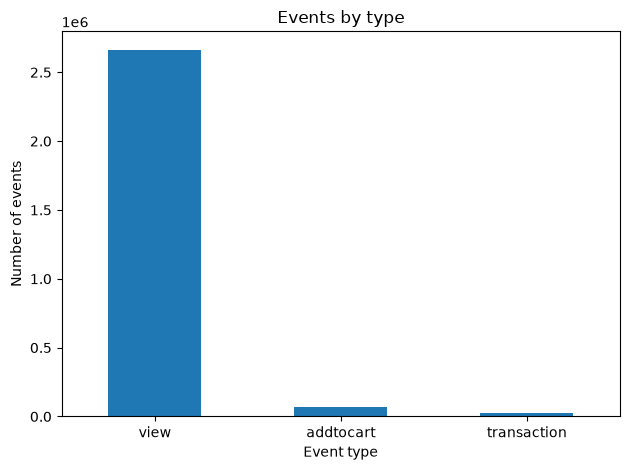

In [74]:
event_counts.plot(
    x="event_type",
    y="event_count",
    kind="bar",
    legend=False,
    xlabel="Event type",
    ylabel="Number of events",
    title="Events by type",
    rot=0
)
plt.tight_layout()
plt.show()

The labels are `view`, `addtocart`, and `transaction`: product views, cart additions, and recorded purchases. Views dominate, so the event totals alone do not show what share of views led to a purchase.

## Activity per user

In [75]:
user_activity = con.execute("""
    SELECT user_id, COUNT(*) AS event_count
    FROM events
    GROUP BY user_id
""").df()

user_activity["event_count"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
)

count    1.407580e+06
mean     1.958042e+00
std      1.258049e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      3.000000e+00
99%      1.300000e+01
max      7.757000e+03
Name: event_count, dtype: float64

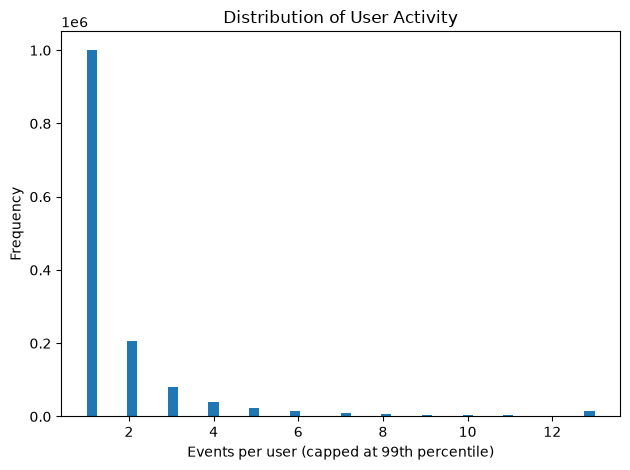

In [76]:
user_activity["event_count"].clip(
    upper=user_activity["event_count"].quantile(0.99)
).plot(
    kind="hist",
    bins=50,
    xlabel="Events per user (capped at 99th percentile)",
    title="Distribution of User Activity"
)

plt.tight_layout()
plt.show()

Most visitors have very short histories in this log. The long upper tail means a small number of visitors are much more active, so the mean is less representative than the median.

## Activity over time

In [77]:
daily_activity = con.execute("""
    SELECT
        CAST(event_timestamp AS DATE) AS event_date,
        COUNT(*) AS event_count,
        COUNT(DISTINCT user_id) AS active_users
    FROM events
    GROUP BY event_date
    ORDER BY event_date
""").df()

daily_activity.head()

,event_date,event_count,active_users
0,2015-05-02,3342,1956
1,2015-05-03,17389,9985
2,2015-05-04,20533,11689
3,2015-05-05,23016,13193
4,2015-05-06,23628,13458


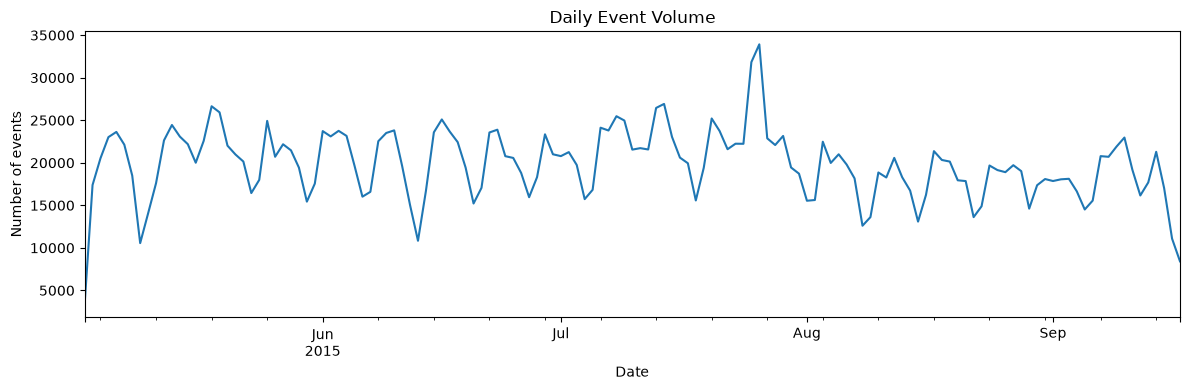

In [78]:
daily_activity.plot(
    x="event_date",
    y="event_count",
    legend=False,
    xlabel="Date",
    ylabel="Number of events",
    title="Daily Event Volume",
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

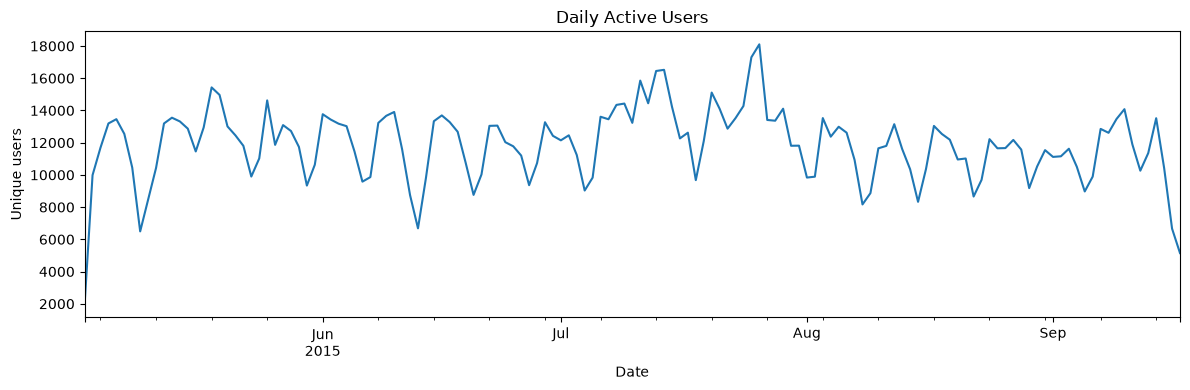

In [79]:
daily_activity.plot(
    x="event_date",
    y="active_users",
    legend=False,
    xlabel="Date",
    ylabel="Unique users",
    title="Daily Active Users",
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

The daily charts show how recorded activity changes over the observation period. A daily active-user count is a count of visitors with at least one event that day, not a measure of repeat retention.

## Data quality

In [80]:
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE user_id IS NULL) AS missing_user_id,
        COUNT(*) FILTER (WHERE event_timestamp IS NULL) AS missing_timestamp,
        COUNT(*) FILTER (WHERE event_type IS NULL) AS missing_event_type,
        COUNT(*) FILTER (WHERE item_id IS NULL) AS missing_item_id
    FROM events
""").df()

,total_rows,missing_user_id,missing_timestamp,missing_event_type,missing_item_id
0,2756101,0,0,0,0


In [81]:
con.execute("""
    SELECT
        COUNT(*) AS duplicate_groups,
        SUM(n - 1) AS extra_rows
    FROM (
        SELECT COUNT(*) AS n
        FROM events
        GROUP BY user_id, event_timestamp, event_type, item_id
        HAVING COUNT(*) > 1
    )
""").df()

,duplicate_groups,extra_rows
0,458,460.0


In [82]:
con.execute("""
    SELECT
        MIN(event_timestamp) AS first_event,
        MAX(event_timestamp) AS last_event,
        COUNT(*) FILTER (WHERE event_timestamp > CURRENT_TIMESTAMP) AS future_events
    FROM events
""").df()

,first_event,last_event,future_events
0,2015-05-02 20:00:04.384000-07:00,2015-09-17 19:59:47.788000-07:00,0


There are 460 extra rows with the same visitor, timestamp, event, and item values. This is a small number relative to the full log, but identical fields do not prove an event is accidental, so I leave them in for now.

## Observation window

In [83]:
con.execute("""
    SELECT
        MIN(event_timestamp) AS first_event,
        MAX(event_timestamp) AS last_event,
        DATE_DIFF(
            'day',
            CAST(MIN(event_timestamp) AS DATE),
            CAST(MAX(event_timestamp) AS DATE)
        ) + 1 AS calendar_days
    FROM events
""").df()

,first_event,last_event,calendar_days
0,2015-05-02 20:00:04.384000-07:00,2015-09-17 19:59:47.788000-07:00,139


In [84]:
user_history = con.execute("""
    SELECT
        user_id,
        MIN(event_timestamp) AS first_seen,
        MAX(event_timestamp) AS last_seen,
        DATE_DIFF(
            'day',
            CAST(MIN(event_timestamp) AS DATE),
            CAST(MAX(event_timestamp) AS DATE)
        ) AS observed_span_days
    FROM events
    GROUP BY user_id
""").df()

user_history["observed_span_days"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
)

count    1.407580e+06
mean     2.375158e+00
std      1.163148e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
90%      1.000000e+00
max      1.380000e+02
Name: observed_span_days, dtype: float64

The median observed span is 0 days and the 90th percentile is 1 day. Most visitors therefore appear on only one or two calendar dates in the log. A return definition based on a longer window will need to account for the shorter follow-up available to visitors first seen near the end.

## Takeaways

1. The dataset contains 2.76 million events from 1.41 million visitors. Most visitors have very little recorded activity: the median is 1 event, and 90% have 3 or fewer.

2. Views account for 96.7% of events, compared with 2.5% add-to-cart events and 0.8% transactions. There are no missing values in the four fields checked. I found 460 extra rows with the same user, timestamp, event type, and item. I left them in because identical records aren't necessarily errors.

3. The data covers May 2 to September 17, 2015 (139 days). Visitors first seen near the end have less time to return before the data ends, which matters when defining the retention window. These counts describe individual events, not conversion rates, since sessions haven't been identified.